# OrientationJ Analysis (Python GST)

Faithful Python reproduction of **OrientationJ Analysis** on the 16 images of
[../orientationj-test-images](../orientationj-test-images), with the plugin defaults: **cubic-spline gradient**
(the plugin default, gradient code 0), structure-tensor local window **σ = 1**,
ε = 0.001. The port is in [orientationj.py](orientationj.py).

For every image, `results/analysis/` receives four maps:

| file | content |
|---|---|
| `<name>-orientation.tif` | orientation θ in degrees, in [−90, +90], 32-bit float |
| `<name>-coherency.tif` | coherency in [0, 1], 32-bit float |
| `<name>-energy.tif` | tensor trace (energy), raw scale, 32-bit float |
| `<name>-survey.png` | HSB color survey — hue = orientation, saturation = coherency, brightness = input |

The notebook ends with the summary page **`results/analysis/analysis-summary.md`**,
one figure per image.

*Validation: on `collagen.tif` (spline, σ = 2) the Python coherency map is bitwise
identical to the Java plugin output; the orientation map matches to 8·10⁻⁶ degrees.*

In [1]:
import datetime
import glob
import os

import numpy as np
import matplotlib.pyplot as plt
import tifffile

import orientationj as oj

SIGMA = 1.0      # structure-tensor Gaussian window (OrientationJ default)
EPSILON = 0.001  # coherency regularisation (OrientationJ default)
INPUT = os.path.join('..', 'orientationj-test-images')
MASKS = os.path.join(INPUT, 'masks')
OUTPUT = os.path.join('results', 'analysis')
os.makedirs(OUTPUT, exist_ok=True)

plt.rcParams.update({
    'figure.facecolor': 'white', 'font.size': 10, 'axes.titlesize': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#cfcec6', 'grid.color': '#e8e8e4', 'grid.linewidth': 0.8,
    'text.color': '#3a3a37', 'axes.labelcolor': '#3a3a37',
    'xtick.color': '#6b6a63', 'ytick.color': '#6b6a63'})
ACCENT = '#4878a8'

In [2]:
paths = sorted(glob.glob(os.path.join(INPUT, 'images', '*.tif')))
images = {os.path.splitext(os.path.basename(p))[0]: oj.load(p) for p in paths}
for name, image in images.items():
    print(f'{name:42s} {image.shape}')
names = list(images.keys())
print(len(names), 'images')

masks = {name: tifffile.imread(os.path.join(MASKS, name + '.tif')) > 0
         for name in names}

cell_aemisegger                            (728, 728)
collagen                                   (512, 512)
dendrochronology                           (512, 512)
fibronectin_arafat_plos2025                (1024, 1024)
fibrous_tissues_fibero2024                 (2048, 2048)
fiji_directionality_montage                (1536, 1536)
nanofiber_fiji_diameterj                   (512, 512)
polymer_slice_quanfima2018                 (600, 600)
synthetic_chirp_1024                       (1024, 1024)
synthetic_filaments_512                    (512, 512)
synthetic_nematic_512                      (512, 512)
synthetic_noise_512                        (512, 512)
synthetic_rings_dither_512                 (512, 512)
synthetic_spiral_512                       (512, 512)
synthetic_wave_512                         (512, 512)
z_artificial_fibers                        (512, 683)
16 images


In [3]:
features = {}
surveys = {}
for name, image in images.items():
    f = oj.analysis(image, sigma=SIGMA, epsilon=EPSILON)
    surveys[name] = oj.survey(image, f)
    tifffile.imwrite(os.path.join(OUTPUT, name + '-orientation.tif'),
                     np.degrees(f['orientation']).astype(np.float32))
    tifffile.imwrite(os.path.join(OUTPUT, name + '-coherency.tif'), f['coherency'])
    tifffile.imwrite(os.path.join(OUTPUT, name + '-energy.tif'), f['energy'])
    plt.imsave(os.path.join(OUTPUT, name + '-survey.png'), surveys[name])
    features[name] = f
    print(f'analyzed {name:42s} {image.shape}')

analyzed cell_aemisegger                            (728, 728)
analyzed collagen                                   (512, 512)


analyzed dendrochronology                           (512, 512)


analyzed fibronectin_arafat_plos2025                (1024, 1024)


analyzed fibrous_tissues_fibero2024                 (2048, 2048)


analyzed fiji_directionality_montage                (1536, 1536)
analyzed nanofiber_fiji_diameterj                   (512, 512)


...

analyzed synthetic_chirp_1024                       (1024, 1024)
analyzed synthetic_filaments_512                    (512, 512)


analyzed synthetic_nematic_512                      (512, 512)
analyzed synthetic_noise_512                        (512, 512)


analyzed synthetic_rings_dither_512                 (512, 512)
analyzed synthetic_spiral_512                       (512, 512)


analyzed synthetic_wave_512                         (512, 512)


analyzed z_artificial_fibers                        (512, 683)


## Color surveys

Hue = orientation (−90° red → cyan → +90° red), saturation = coherency,
brightness = input image: saturated colors mark strongly oriented structures.

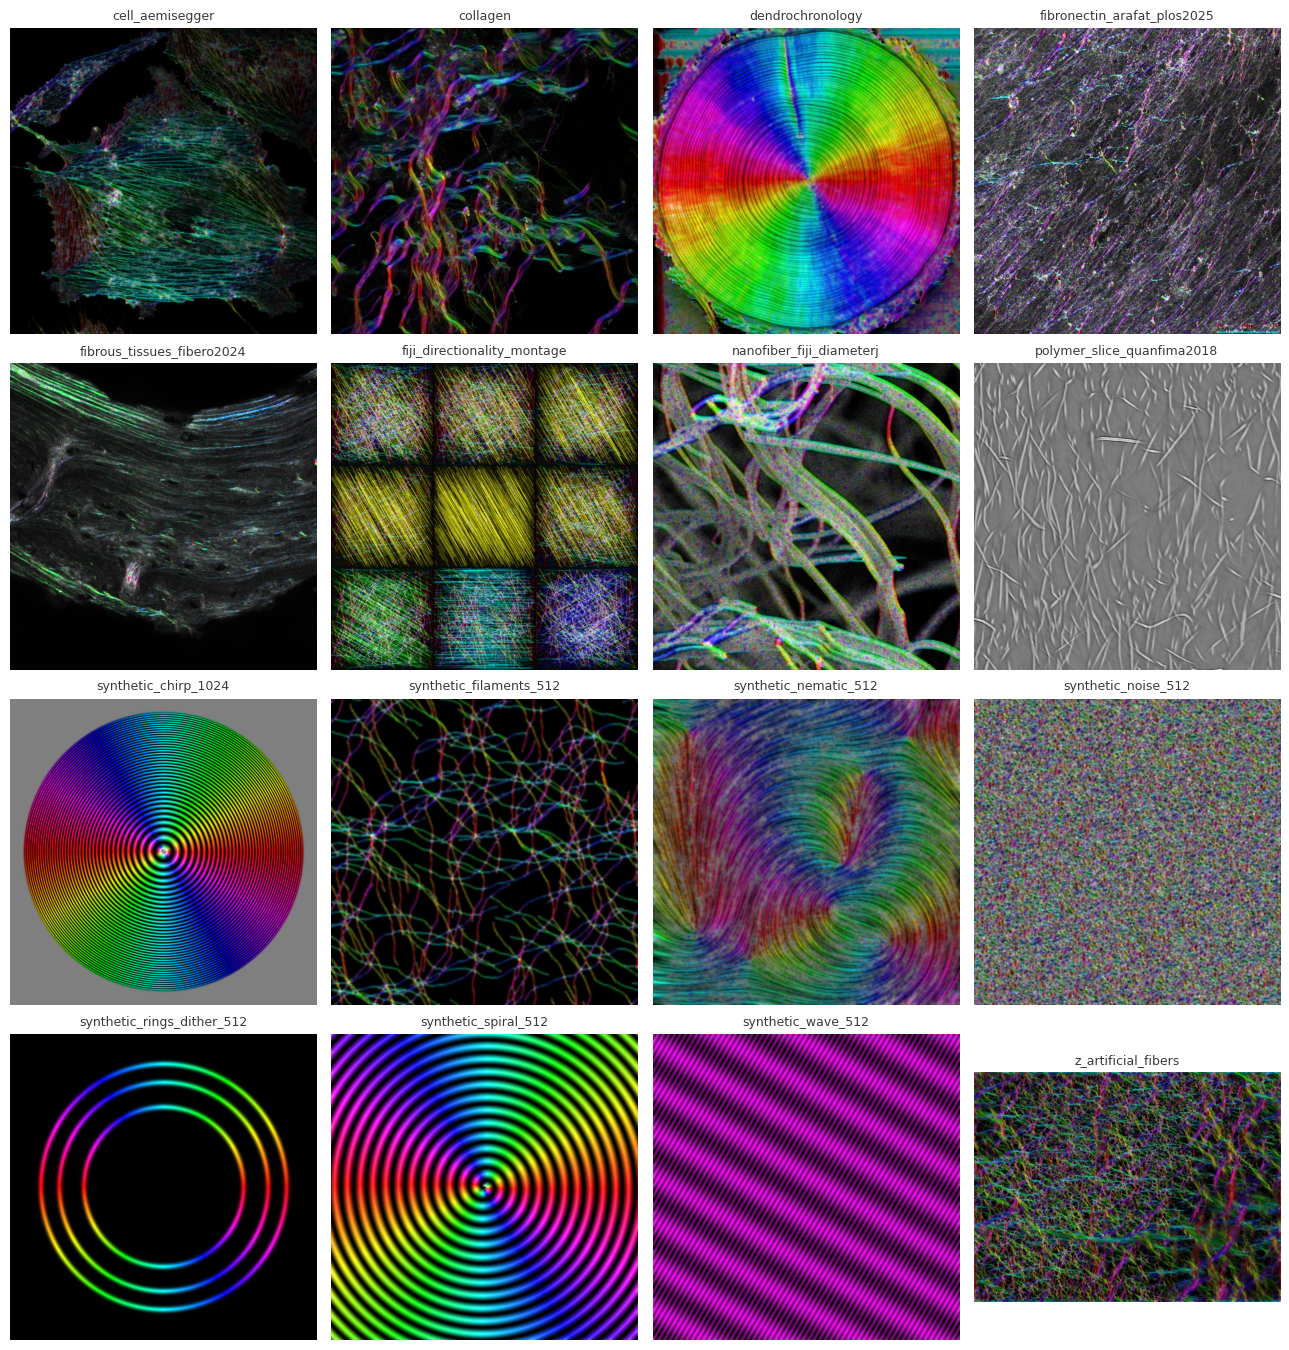

In [4]:
rows = -(-len(names) // 4)
fig, axes = plt.subplots(rows, 4, figsize=(13, 3.4 * rows))
for ax in axes.flat:
    ax.axis('off')
for ax, name in zip(axes.flat, names):
    ax.imshow(surveys[name])
    ax.set_title(name, fontsize=9)
fig.tight_layout()
plt.show()

## Summary page

One figure per image, six panels on 2 rows × 3 columns: input, precomputed mask,
color survey / orientation, coherency and energy maps (energy display clipped at
its 99.5th percentile). Written to `results/analysis/analysis-summary.md`
(figures in `results/analysis/figures/`).

In [5]:
FIGURES = os.path.join(OUTPUT, 'figures')
os.makedirs(FIGURES, exist_ok=True)

lines = [
    '# OrientationJ Analysis — Python GST',
    '',
    '*Generated on ' + datetime.date.today().isoformat()
        + ' by [analysis.ipynb](../../analysis.ipynb).*',
    '',
    '- Gradient: cubic spline (plugin default), structure-tensor window sigma = '
        + str(SIGMA) + ', epsilon = ' + str(EPSILON),
    '- Per image: orientation [deg], coherency [0, 1], energy (32-bit TIFF) and the',
    '  HSB color survey (hue = orientation, sat = coherency, brightness = image)',
    '- Validation: on collagen.tif (spline, sigma = 2) the coherency map is bitwise',
    '  identical to the Java plugin; orientation matches to 8e-6 deg',
    '']

for name in names:
    f = features[name]
    image = images[name]

    fig, axes = plt.subplots(2, 3, figsize=(13.5, 8.4))
    axes[0, 0].imshow(image, cmap='gray')
    axes[0, 0].set_title('input')
    axes[0, 1].imshow(masks[name], cmap='gray', vmin=0, vmax=1)
    axes[0, 1].set_title('mask')
    axes[0, 2].imshow(surveys[name])
    axes[0, 2].set_title('color survey')
    m0 = axes[1, 0].imshow(np.degrees(f['orientation']), cmap='hsv', vmin=-90, vmax=90)
    axes[1, 0].set_title('orientation [deg]')
    m1 = axes[1, 1].imshow(f['coherency'], cmap='gray', vmin=0, vmax=1)
    axes[1, 1].set_title('coherency')
    m2 = axes[1, 2].imshow(f['energy'], cmap='gray', vmin=0,
                           vmax=np.percentile(f['energy'], 99.5))
    axes[1, 2].set_title('energy (clip p99.5)')
    for ax in axes.flat:
        ax.axis('off')
    for m, ax in ((m0, axes[1, 0]), (m1, axes[1, 1]), (m2, axes[1, 2])):
        fig.colorbar(m, ax=ax, fraction=0.045, pad=0.02).ax.tick_params(labelsize=7)
    fig.savefig(os.path.join(FIGURES, name + '.png'), dpi=130, bbox_inches='tight')
    plt.close(fig)

    lines += ['## ' + name + ' — ' + str(image.shape[1]) + ' × ' + str(image.shape[0]),
              '', '![' + name + '](figures/' + name + '.png)', '']

page_path = os.path.join(OUTPUT, 'analysis-summary.md')
open(page_path, 'w').write('\n'.join(lines))
print('written', page_path)

written results/analysis/analysis-summary.md
